# 2 · CNNs and transfer learning

Train a CNN on Fashion-MNIST. Compare it with the MLP.
Then use a pretrained ResNet-18 to classify pet breeds (a harder data set) and inspect its predictions.

## Setup

In [8]:
import os, re, time, math, random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from PIL import Image

QUICK = True
SEED  = 42
IMAGE_SIZE = 28

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("/content/data") if Path("/content").is_dir() else Path("./data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 100
print("device :", device)
print("QUICK  :", QUICK)
if device.type == "cuda":
    print("gpu    :", torch.cuda.get_device_name(0))


device : cuda
QUICK  : True
gpu    : Tesla T4


In [9]:
@torch.no_grad()
def accuracy(model, X, y, batch_size=256):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        pred = model(X[i:i+batch_size].to(device)).argmax(1).cpu()
        correct += (pred == y[i:i+batch_size]).sum().item()
    return correct / len(X)


def train(model, X, y, epochs=10, lr=1e-3, batch_size=64, X_val=None, y_val=None,
          criterion=None, weight_decay=0.0, log=True):
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)
    criterion = criterion or nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        total, correct, running = 0, 0, 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()          # 1. forget the gradients of the previous batch
            out  = model(xb)               # 2. forward pass -> raw scores (logits)
            loss = criterion(out, yb)      # 3. how wrong are we?
            loss.backward()                # 4. backprop: fill .grad for every weight
            optimizer.step()               # 5. nudge every weight downhill

            running += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total   += xb.size(0)

        history["train_loss"].append(running / total)
        history["train_acc"].append(correct / total)
        if X_val is not None:
            history["val_acc"].append(accuracy(model, X_val, y_val))
        if log:
            msg = f"epoch {epoch+1}/{epochs} | train loss {running/total:.4f} | train acc {correct/total:.3f}"
            if X_val is not None:
                msg += f" | val acc {history['val_acc'][-1]:.3f}"
            print(msg + f" | {time.time()-t0:.1f}s")
    return history


def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    axes[0].plot(history["train_loss"])
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("training loss")
    axes[1].plot(history["train_acc"], label="train")
    if history["val_acc"]:
        axes[1].plot(history["val_acc"], label="val")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_ylim(0, 1)
    axes[1].set_title("train vs validation accuracy"); axes[1].legend()
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()


def show_images(images, titles=None, ncols=5, title=None):
    n = len(images)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.7, nrows * 1.9))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for i, img in enumerate(images):
        arr = img.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()
        if arr.shape[2] == 1:
            arr = arr[..., 0]
        axes[i].imshow(arr)
        if titles is not None:
            axes[i].set_title(titles[i], fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

## 1. The same task with a CNN

We use the same Fashion-MNIST data as notebook 1. Each image has one channel.
A 3×3 filter has nine weights. The CNN reuses each filter across image positions.

In [10]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
N_CLASSES = len(CLASS_NAMES)


def load_fashion(size=IMAGE_SIZE):
    tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])
    train_base = torchvision.datasets.FashionMNIST(str(DATA_DIR), train=True, download=True, transform=tf)
    test_base = torchvision.datasets.FashionMNIST(str(DATA_DIR), train=False, download=True, transform=tf)

    def to_tensor(ds, limit):
        n = len(ds) if limit is None else min(limit, len(ds))
        X = torch.empty(n, 1, size, size)
        y = torch.empty(n, dtype=torch.long)
        for i in range(n):
            xi, yi = ds[i]
            X[i], y[i] = xi, yi
            if (i + 1) % 4000 == 0:
                print(f"  decoded {i+1}/{n}")
        return X, y

    X_tr_all, y_tr_all = to_tensor(train_base, 8_000 if QUICK else None)
    X_te, y_te = to_tensor(test_base, 2_000 if QUICK else None)
    return X_tr_all, y_tr_all, X_te, y_te


X_tr_all, y_tr_all, X_te, y_te = load_fashion()

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_tr_all), generator=g)
n_val = int(0.1 * len(perm))
val_idx, train_idx = perm[:n_val], perm[n_val:]

mu = X_tr_all[train_idx].mean(dim=(0, 2, 3), keepdim=True)
sd = X_tr_all[train_idx].std(dim=(0, 2, 3), keepdim=True)
norm = lambda z: (z - mu) / sd

X, y           = norm(X_tr_all[train_idx]), y_tr_all[train_idx]
X_val, y_val   = norm(X_tr_all[val_idx]),   y_tr_all[val_idx]
X_test, y_test = norm(X_te),                y_te

print(f"train {len(X)} | val {len(X_val)} | test {len(X_test)} | classes {N_CLASSES}")

  decoded 4000/8000
  decoded 8000/8000
train 7200 | val 800 | test 2000 | classes 10


In [11]:
def make_cnn():
    # Three 2x pooling layers floor the side length three times.
    feature_side = IMAGE_SIZE // 8
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(64 * feature_side * feature_side, 64), nn.ReLU(),
        nn.Linear(64, N_CLASSES),
    )

cnn = make_cnn().to(device)
cnn

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=576, out_features=64, bias=True)
  (11): ReLU()
  (12): Linear(in_features=64, out_features=10, bias=True)
)

In [12]:
x = torch.zeros(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=device)

cnn.eval()
with torch.no_grad():
    for i, layer in enumerate(cnn):
        print(f"{i:2} {type(layer).__name__:16} input: {tuple(x.shape)}")
        try:
            x = layer(x)
        except RuntimeError:
            print(f"   Failed at layer {i}: {layer}")
            raise
        print(f"   output: {tuple(x.shape)}")

 0 Conv2d           input: (1, 1, 28, 28)
   output: (1, 16, 28, 28)
 1 ReLU             input: (1, 16, 28, 28)
   output: (1, 16, 28, 28)
 2 MaxPool2d        input: (1, 16, 28, 28)
   output: (1, 16, 14, 14)
 3 Conv2d           input: (1, 16, 14, 14)
   output: (1, 32, 14, 14)
 4 ReLU             input: (1, 32, 14, 14)
   output: (1, 32, 14, 14)
 5 MaxPool2d        input: (1, 32, 14, 14)
   output: (1, 32, 7, 7)
 6 Conv2d           input: (1, 32, 7, 7)
   output: (1, 64, 7, 7)
 7 ReLU             input: (1, 64, 7, 7)
   output: (1, 64, 7, 7)
 8 MaxPool2d        input: (1, 64, 7, 7)
   output: (1, 64, 3, 3)
 9 Flatten          input: (1, 64, 3, 3)
   output: (1, 576)
10 Linear           input: (1, 576)
   output: (1, 64)
11 ReLU             input: (1, 64)
   output: (1, 64)
12 Linear           input: (1, 64)
   output: (1, 10)


epoch 1/8 | train loss 1.0567 | train acc 0.621 | val acc 0.745 | 0.7s
epoch 2/8 | train loss 0.6015 | train acc 0.773 | val acc 0.816 | 0.3s
epoch 3/8 | train loss 0.4930 | train acc 0.816 | val acc 0.805 | 0.3s
epoch 4/8 | train loss 0.4432 | train acc 0.839 | val acc 0.845 | 0.3s
epoch 5/8 | train loss 0.3942 | train acc 0.856 | val acc 0.853 | 0.3s
epoch 6/8 | train loss 0.3688 | train acc 0.864 | val acc 0.841 | 0.3s
epoch 7/8 | train loss 0.3475 | train acc 0.871 | val acc 0.844 | 0.3s
epoch 8/8 | train loss 0.3235 | train acc 0.883 | val acc 0.860 | 0.3s


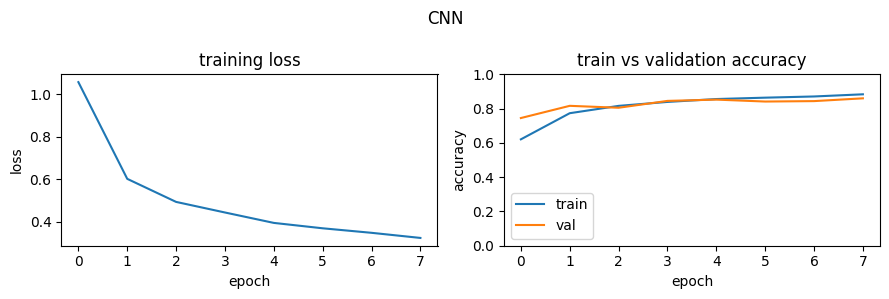

In [13]:
history = train(cnn, X, y, epochs=8, lr=1e-3, X_val=X_val, y_val=y_val)
plot_history(history, "CNN")

input tensor : (1, 1, 28, 28)
after conv1  : (1, 16, 28, 28)  (1 image, 16 filters, 64x64 each)


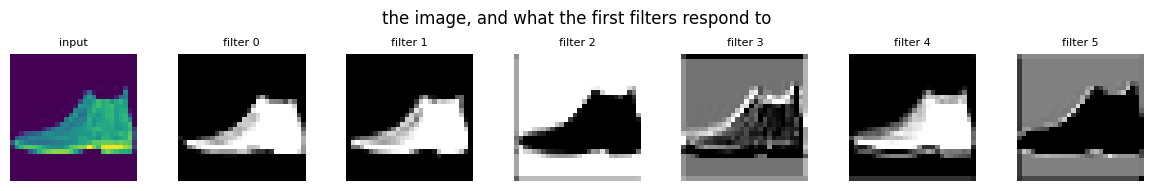

In [14]:
img = X_test[:1].to(device)

with torch.no_grad():
    acts = cnn[0](img)

# raw (un-standardised) input for display
disp = X_te[0]
print("input tensor :", tuple(img.shape))
print("after conv1  :", tuple(acts.shape), " (1 image, 16 filters, 64x64 each)")

show_images([disp] + [acts[0, c].unsqueeze(0).repeat(3, 1, 1).cpu() for c in range(6)],
            titles=["input"] + [f"filter {c}" for c in range(6)],
            ncols=7, title="the image, and what the first filters respond to")

## 3. Compare the models

Both models use the same training and test images. Compare test accuracy, AUC and parameter count.

In [ ]:
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * IMAGE_SIZE * IMAGE_SIZE, 256),
    nn.ReLU(),
    nn.Linear(256, N_CLASSES),
).to(device)
train(mlp, X, y, epochs=10, lr=1e-3, log=False)

from sklearn.metrics import roc_auc_score

@torch.no_grad()
def probabilities(model, X):
    model.eval()
    return torch.cat([
        torch.softmax(model(X[i:i+256].to(device)), dim=1).cpu()
        for i in range(0, len(X), 256)
    ])

mlp_probs = probabilities(mlp, X_test)
cnn_probs = probabilities(cnn, X_test)
mlp_acc = (mlp_probs.argmax(1) == y_test).float().mean().item()
cnn_acc = (cnn_probs.argmax(1) == y_test).float().mean().item()
mlp_auc = roc_auc_score(y_test.numpy(), mlp_probs.numpy(), multi_class="ovr")
cnn_auc = roc_auc_score(y_test.numpy(), cnn_probs.numpy(), multi_class="ovr")

print(f"{'model':<8}{'parameters':>14}{'test accuracy':>16}{'AUC':>8}")
print(f"{'MLP':<8}{n_params(mlp):>14,}{mlp_acc:>16.3f}{mlp_auc:>8.3f}")
print(f"{'CNN':<8}{n_params(cnn):>14,}{cnn_acc:>16.3f}{cnn_auc:>8.3f}")

model       parameters   test accuracy     AUC
MLP            203,530           0.854   0.987
CNN             60,874           0.863   0.988


## 4. Cat breeds

In [16]:

CAT_BREEDS = {
    "abyssinian", "bengal", "birman", "bombay", "british_shorthair",
    "egyptian_mau", "maine_coon", "persian", "ragdoll", "russian_blue",
    "siamese", "sphinx",
}

def breed_from_path(path):
    """'Abyssinian_12.jpg' -> 'abyssinian'."""
    return Path(path).stem.rsplit("_", 1)[0].lower()


def pet_paths(split):
    base = torchvision.datasets.OxfordIIITPet(
        root=str(DATA_DIR), split=split, target_types="category", download=True
    )
    paths = getattr(base, "_images", None) or getattr(base, "images", None)
    if not paths:
        raise RuntimeError("Could not read the image list from OxfordIIITPet")
    return [str(p) for p in paths]


def decode(paths, size=IMAGE_SIZE):
    tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])
    X = torch.empty(len(paths), 3, size, size)
    for i, p in enumerate(paths):
        X[i] = tf(Image.open(p).convert("RGB"))
        if (i + 1) % 1500 == 0:
            print(f"  decoded {i+1}/{len(paths)}")
    return X

In [17]:
trainval_paths = pet_paths("trainval")
test_paths     = pet_paths("test")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
PROBE_SIZE = 160

all_breeds = sorted({breed_from_path(p) for p in trainval_paths})
breed_to_idx = {b: i for i, b in enumerate(all_breeds)}
print(f"{len(all_breeds)} breeds, e.g. {all_breeds[:6]} ...")

probe_tf = transforms.Compose([
    transforms.Resize((PROBE_SIZE, PROBE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def decode_probe(paths, limit=None):
    paths = paths[:limit] if limit else paths
    Xp = torch.empty(len(paths), 3, PROBE_SIZE, PROBE_SIZE)
    for i, p in enumerate(paths):
        Xp[i] = probe_tf(Image.open(p).convert("RGB"))
        if (i + 1) % 1500 == 0:
            print(f"  decoded {i+1}/{len(paths)}")
    return Xp, torch.tensor([breed_to_idx[breed_from_path(p)] for p in paths])

limit = 1200 if QUICK else None
Xb_tr_all, yb_tr = decode_probe(trainval_paths, limit)
Xb_te, yb_te     = decode_probe(test_paths, 600 if QUICK else None)

# reuse the same train/val split indices as before, clipped to what we decoded
tr = [i for i in train_idx if i < len(Xb_tr_all)]
va = [i for i in val_idx if i < len(Xb_tr_all)]
Xb_tr, yb_trv = Xb_tr_all[tr], yb_tr[tr]
Xb_va, yb_vav = Xb_tr_all[va], yb_tr[va]
print(f"breed task: train {len(Xb_tr)} | val {len(Xb_va)} | test {len(Xb_te)}")

100%|██████████| 792M/792M [01:09<00:00, 11.4MB/s]  
100%|██████████| 19.2M/19.2M [00:02<00:00, 7.44MB/s]


37 breeds, e.g. ['abyssinian', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'bengal'] ...
breed task: train 1079 | val 121 | test 600


Here we use a pretrained model and only train the linear head.

In [18]:
backbone = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
backbone = backbone.to(device).eval()
for p in backbone.parameters():
    p.requires_grad_(False)          # frozen: we only use it as a feature extractor
backbone.fc = nn.Identity()          # drop the 1000-class head

@torch.no_grad()
def features(model, X, batch_size=64):
    out = []
    for i in range(0, len(X), batch_size):
        out.append(model(X[i:i+batch_size].to(device)).cpu())
    return torch.cat(out)

t0 = time.time()
F_tr, F_va, F_te = features(backbone, Xb_tr), features(backbone, Xb_va), features(backbone, Xb_te)
print(f"exported features in {time.time()-t0:.1f}s | one {tuple(F_tr.shape[1:])} vector per photo")

class Probe(nn.Module):
    def __init__(self, dim, n_classes):
        super().__init__()
        self.fc = nn.Linear(dim, n_classes)
    def forward(self, x):
        return self.fc(F.normalize(x, dim=1))

head = Probe(F_tr.shape[1], len(all_breeds)).to(device)
opt = torch.optim.Adam(head.parameters(), lr=1e-3)
for step in range(1000):
    head.train()
    opt.zero_grad()
    loss = nn.functional.cross_entropy(head(F_tr.to(device)), yb_trv.to(device))
    loss.backward()
    opt.step()

with torch.no_grad():
    tr_acc = (head(F_tr.to(device)).argmax(1).cpu() == yb_trv).float().mean().item()
    va_acc = (head(F_va.to(device)).argmax(1).cpu() == yb_vav).float().mean().item()
    te_acc = (head(F_te.to(device)).argmax(1).cpu() == yb_te).float().mean().item()
    
print(f"37-breed accuracy | train {tr_acc:.3f} | val {va_acc:.3f} | test {te_acc:.3f}   (chance = {1/37:.3f})")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 119MB/s] 


exported features in 1.1s | one (512,) vector per photo
37-breed accuracy | train 0.957 | val 0.942 | test 0.807   (chance = 0.027)


activation matrix (300, 256)


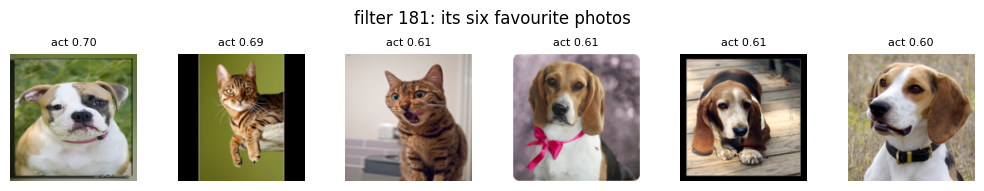

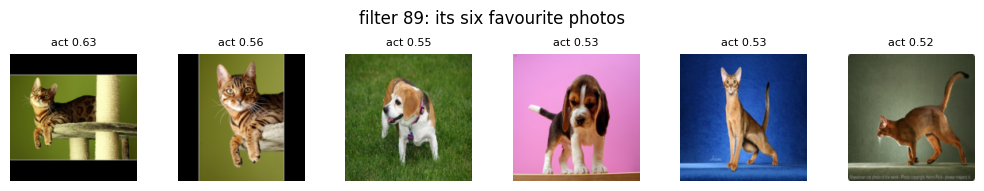

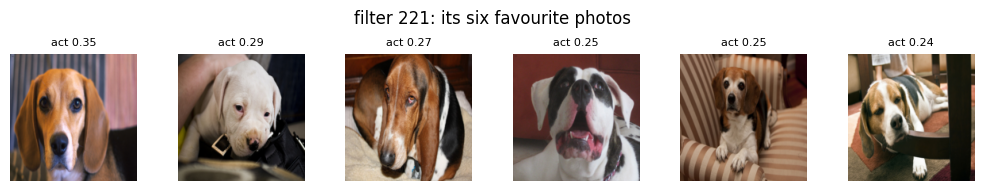

In [19]:
N_PROBE = 300 if QUICK else 600
g2 = torch.Generator().manual_seed(7)
probe_idx = torch.randperm(len(Xb_te), generator=g2)[:N_PROBE]   # the test list is sorted by breed!
X_probe = Xb_te[probe_idx]

store = {}
h = backbone.layer3.register_forward_hook(lambda m, i, o: store.__setitem__("a", o.mean(dim=(2, 3)).detach().cpu()))
acts = []
with torch.no_grad():
    for i in range(0, len(X_probe), 32):
        backbone(X_probe[i:i+32].to(device))
        acts.append(store["a"].clone())
h.remove()

A = torch.cat(acts)      # (photos, 256 channels): one number per channel per photo
print(f"activation matrix {tuple(A.shape)}")

mean_t = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_t  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
raw_probe = (X_probe * std_t + mean_t).clamp(0, 1)

order = A.var(dim=0).argsort(descending=True)     # channels that vary most across our photos
channels = [int(c) for c in order[[0, 40, 120]]]

# The three grids show images that activate selected convolutional filters most strongly.

for ch in channels:
    top = A[:, ch].argsort(descending=True)[:6]
    show_images([raw_probe[i] for i in top.tolist()],
                titles=[f"act {A[i, ch]:.2f}" for i in top.tolist()],
                ncols=6, title=f"filter {ch}: its six favourite photos")

## 5. Saliency and Grad-CAM

Saliency uses input gradients to highlight pixels that affect the class score.
Grad-CAM uses gradients from the final convolution layer to highlight image regions.

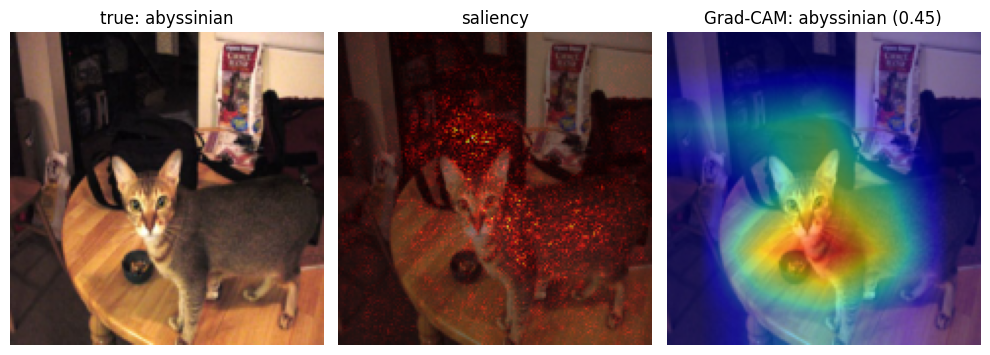

In [20]:
full = nn.Sequential(backbone, head).to(device).eval()

def saliency(model, x, class_idx=None):
    x = x.clone().detach().requires_grad_(True)
    out = model(x)
    if class_idx is None:
        class_idx = int(out.argmax(1))
    out[0, class_idx].backward()
    return x.grad.detach().abs().amax(dim=1)[0], class_idx

def gradcam(model, x, target_layer, class_idx=None):
    x = x.clone().detach().requires_grad_(True)   # frozen weights + no grad on the input = no graph
    acts, grads = {}, {}
    h1 = target_layer.register_forward_hook(lambda m, i, o: acts.__setitem__("a", o.detach()))
    h2 = target_layer.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("g", go[0].detach()))
    model.zero_grad()
    out = model(x)
    if class_idx is None:
        class_idx = int(out.argmax(1))
    out[0, class_idx].backward()
    h1.remove(); h2.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), class_idx

idx = 0
x = Xb_te[idx:idx+1].to(device)
with torch.no_grad():
    pred_idx = int(full(x).argmax(1))
    p = torch.softmax(full(x), 1)[0, pred_idx].item()

s, _ = saliency(full, x)
s = F.interpolate(s[None, None], size=x.shape[-2:], mode="bilinear")[0, 0]
cam, _ = gradcam(full, x, backbone.layer4)
img = (Xb_te[idx] * std_t + mean_t).clamp(0, 1)

fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
for a in ax: a.axis("off")
ax[0].imshow(img.permute(1, 2, 0).numpy()); ax[0].set_title(f"true: {all_breeds[int(yb_te[idx])]}")
ax[1].imshow(img.permute(1, 2, 0).numpy()); ax[1].imshow(s.cpu(), cmap="hot", alpha=0.6)
ax[1].set_title("saliency")
ax[2].imshow(img.permute(1, 2, 0).numpy()); ax[2].imshow(cam.cpu(), cmap="jet", alpha=0.5)
ax[2].set_title(f"Grad-CAM: {all_breeds[pred_idx]} ({p:.2f})")
plt.tight_layout(); plt.show()

In [21]:
try:
    from google.colab import files
    from io import BytesIO
    uploaded = files.upload()
    user_img = Image.open(BytesIO(next(iter(uploaded.values())))).convert("RGB")
except Exception as e:
    print("not on Colab, or nothing uploaded -> using a test image:", e)
    user_img = Image.open(test_paths[idx]).convert("RGB")

pil_tf = transforms.Compose([transforms.Resize((PROBE_SIZE, PROBE_SIZE)), transforms.ToTensor()])
show_images([pil_tf(user_img)], ncols=1, title="your input")

with torch.no_grad():
    probs = torch.softmax(full(probe_tf(user_img).unsqueeze(0).to(device)), 1)[0]
for i in probs.argsort(descending=True)[:3].tolist():
    print(f"{all_breeds[i]:<22}{probs[i]:.3f}")

KeyboardInterrupt: 